# Wikipedia recommender: try it

Put the articles you have visited in `VISITED`, as titles or URLs (they can be mixed), then run all
cells (**Run → Run All Cells**). The first run loads the model, which takes a few seconds.

* Titles ignore case, accents and punctuation: `sao paulo` finds *São Paulo*.
* URLs can be desktop or mobile, percent-encoded, or point to a `#section`.
* An article that is not in the 2,200-article corpus is fetched from Wikipedia and processed on the fly.
  Set `FETCH_UNSEEN = False` to stay offline.
* Inputs that cannot be used are listed with the reason and close titles.

In [1]:
VISITED = [
    "Dog",
    "https://en.wikipedia.org/wiki/Cat",
    "Quantum mechanics",
    "Electron",
]
TOP_K = 10
FETCH_UNSEEN = True

In [2]:
import os
from pathlib import Path

# Data paths are relative to the repository root, so run from there wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import pandas as pd
from IPython.display import Markdown, display

from wiki_recommender.recommender import Recommender
from wiki_recommender.visualization import explain, explain_result, plot_visited_heatmap

recommender = Recommender.load(fetch_unseen=FETCH_UNSEEN)

## Recommendations

In [3]:
result = recommender.recommend(VISITED, top_k=TOP_K)
print(result)

Visited: Dog; Cat; Quantum mechanics; Electron
Interests: Dog, Cat | Quantum mechanics, Electron

  #   Score  Title                                   Shared terms
  1   0.580  Photon                                  quantum, particle, photon, elementary
  2   0.539  Atom                                    atom, electron, particle, proton
  3   0.537  Subatomic particle                      subatomic, particle, elementary, quantum
  4   0.519  Atomic, molecular, and optical physics  quantum, electron, atom, physics
  5   0.516  Particle physics                        particle, elementary, quantum, physics
  6   0.469  Mammal                                  mammal, category: mammal, category: animal, species
  7   0.455  Horse                                   domesticate, breed, feral, domesticated
  8   0.450  Sheep                                   category: mammal, domesticate, category: animal, domestic
  9   0.442  Pig                                     domesticate, domesticated

In [4]:
def as_table(result) -> pd.DataFrame:
    rows = [
        {
            "rank": r.rank,
            "title": r.title,
            "score": r.score,
            "topic": r.topic,
            "compared with": ", ".join(r.interest),
            "shared terms": ", ".join(r.shared_terms[:4]),
            "url": r.url,
        }
        for r in result.recommendations
    ]
    return pd.DataFrame(rows).set_index("rank")


as_table(result)

,title,score,topic,compared with,shared terms,url
rank,,,,,,
1,Photon,0.5796,Physical sciences,"Quantum mechanics, Electron","quantum, particle, photon, elementary",https://en.wikipedia.org/wiki/Photon
2,Atom,0.5389,Physical sciences,"Quantum mechanics, Electron","atom, electron, particle, proton",https://en.wikipedia.org/wiki/Atom
3,Subatomic particle,0.5367,Physical sciences,"Quantum mechanics, Electron","subatomic, particle, elementary, quantum",https://en.wikipedia.org/wiki/Subatomic_particle
4,"Atomic, molecular, and optical physics",0.5192,Physical sciences,"Quantum mechanics, Electron","quantum, electron, atom, physics","https://en.wikipedia.org/wiki/Atomic,_molecula..."
5,Particle physics,0.5164,Physical sciences,"Quantum mechanics, Electron","particle, elementary, quantum, physics",https://en.wikipedia.org/wiki/Particle_physics
6,Mammal,0.4689,Biology and health sciences,"Dog, Cat","mammal, category: mammal, category: animal, sp...",https://en.wikipedia.org/wiki/Mammal
7,Horse,0.4553,Biology and health sciences,"Dog, Cat","domesticate, breed, feral, domesticated",https://en.wikipedia.org/wiki/Horse
8,Sheep,0.4498,Biology and health sciences,"Dog, Cat","category: mammal, domesticate, category: anima...",https://en.wikipedia.org/wiki/Sheep
9,Pig,0.4422,Biology and health sciences,"Dog, Cat","domesticate, domesticated, category: mammal, m...",https://en.wikipedia.org/wiki/Pig


## Why these articles?

Each score is the mean similarity to the visited articles of one *interest* (a group of related visited
articles), and that similarity is a weighted sum of two signals: shared words (TF-IDF) and
a sentence embedding. The left chart splits every score by signal, the right one by the visited article
it comes from.

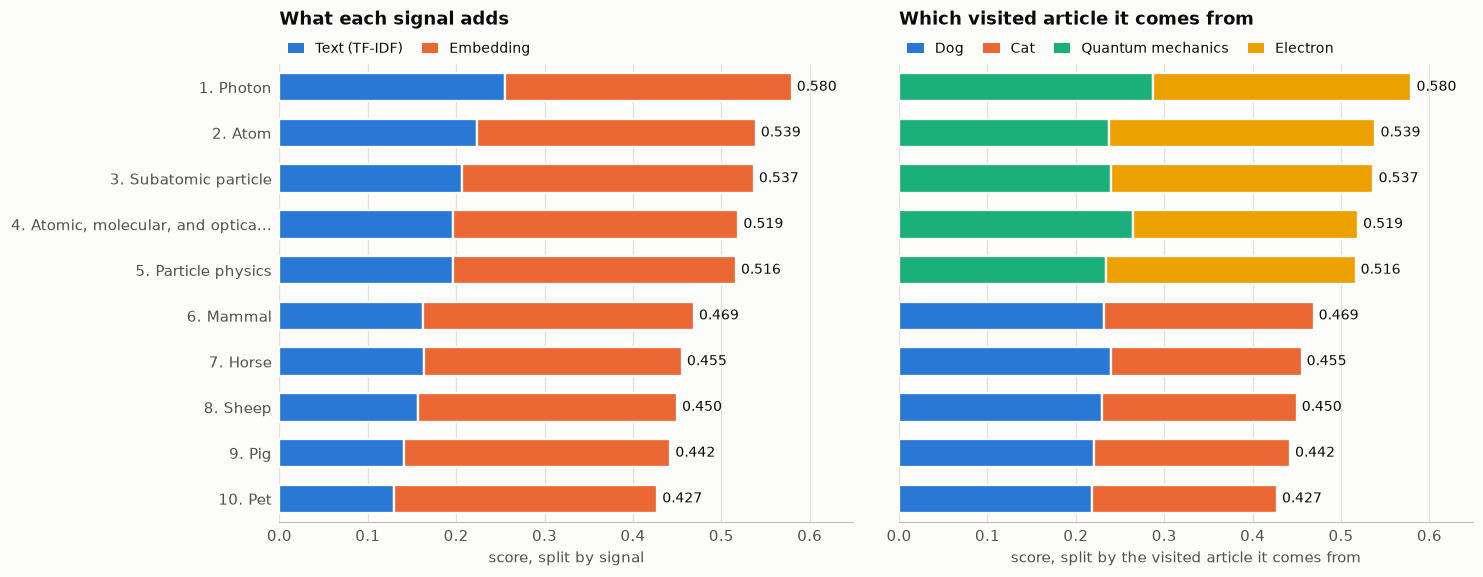

In [5]:
explain_result(result);

The best recommendation in detail: the shared words that add most to its score, then the other signals.

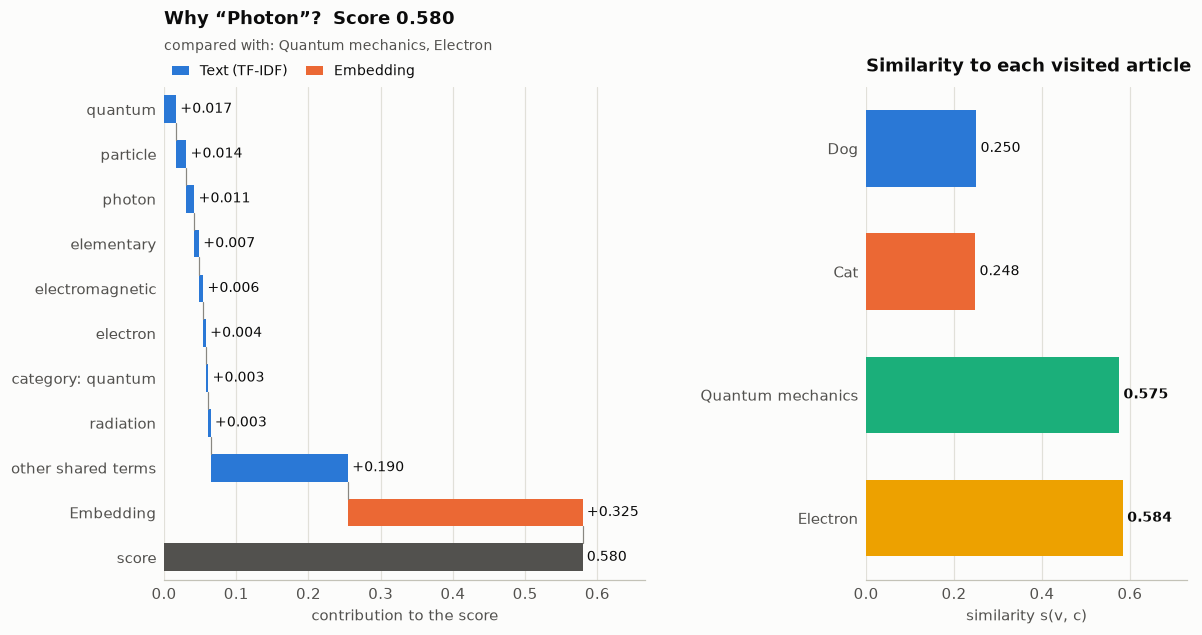

In [6]:
explain(result, rank=1);

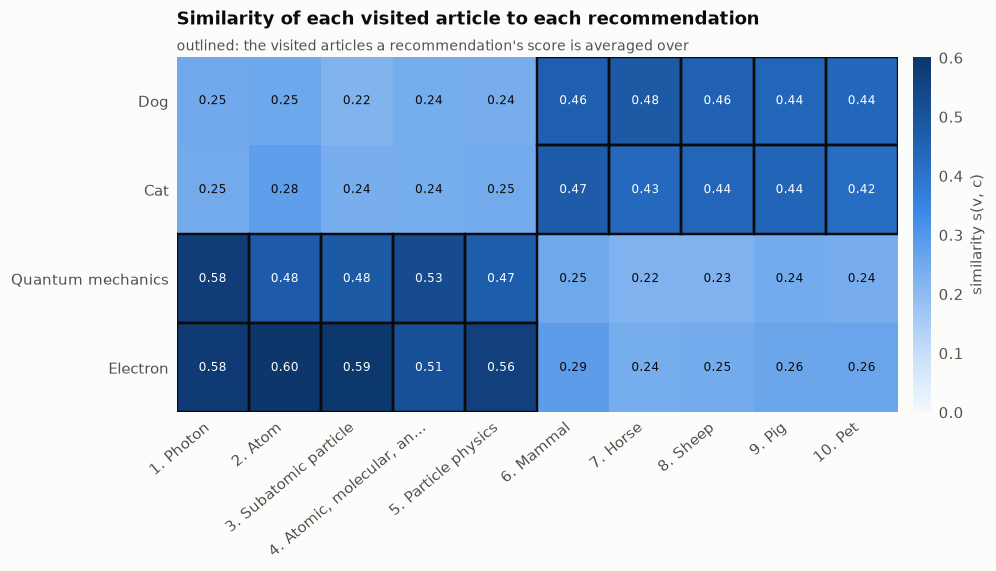

In [7]:
plot_visited_heatmap(result);

## More to try

Any of these can replace `VISITED` above. `recommender.recommend(...)` takes the same arguments as the
command line: `python -m wiki_recommender.recommender "Dog" "Cat" -k 10`.

In [8]:
# Misspelled or ambiguous inputs are reported with suggestions.
print(recommender.recommend(["Elektron", "Mercury", "https://example.com/page"], top_k=5))

! Skipped 'Elektron': this is a disambiguation page; pick one of the meanings it lists. Did you mean: Electron, Skeleton, Electronics?
! Skipped 'Mercury': this is a disambiguation page; pick one of the meanings it lists. Did you mean: Mercury (planet), Memory?
! Skipped 'https://example.com/page': not an English Wikipedia article URL.
No recommendations: none of the inputs matched an article.


In [9]:
# An article outside the corpus is fetched and processed (needs internet; skipped when FETCH_UNSEEN is False).
print(recommender.recommend(["Information retrieval", "Search engine"], top_k=5))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Visited: Information retrieval (fetched); Search engine (fetched)

  #   Score  Title                    Shared terms
  1   0.443  Web browser              web, browser, user, query
  2   0.400  HTML                     web, browser, hyperlink, html
  3   0.390  Internet                 web, internet, hyperlink, user
  4   0.384  Artificial intelligence  search, software, google, user
  5   0.369  Computer science         information, algorithm, query, computer


In [10]:
# The plain mean of all visited articles, instead of splitting the history into interests.
print(recommender.recommend(VISITED, top_k=TOP_K, aggregation="power"))

Visited: Dog; Cat; Quantum mechanics; Electron

  #   Score  Title                                   Shared terms
  1   0.414  Photon                                  quantum, particle, photon, elementary
  2   0.404  Atom                                    atom, electron, particle, proton
  3   0.390  Physics                                 physics, quantum, behavior, particle
  4   0.384  Matter                                  particle, subatomic, atom, quantum
  5   0.383  Subatomic particle                      subatomic, particle, elementary, quantum
  6   0.382  Proton                                  electron, particle, subatomic, proton
  7   0.380  Atomic, molecular, and optical physics  quantum, electron, atom, matter
  8   0.380  Particle physics                        particle, elementary, quantum, physics
  9   0.375  Chemistry                               behavior, chemistry, matter, electron
 10   0.374  Classical mechanics                     quantum, mechanic, relati